In [1]:
import deepSI
from encoder_LPV_models import LPV_single_encoder, LPV_multi_encoder
import time
import batterydl_lpv as dl

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [14]:
# Make sure the version of these packages are the same as below, otherwise the code will not work

from importlib.metadata import version
print(version("pybatteryid"))
print(version("deepSI"))
print(version("scipy"))

3.0.1
0.3.29
1.16.3


d:\Anaconda\envs\OldDeepSI\Lib\site-packages\deepSI\systems\system.py:17: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(file)


Train errors (RMSE, NRMS, MAE) = (4.973 mV, 0.021, 3.002 mV)
Test  errors (RMSE, NRMS, MAE) = (24.097 mV, 0.095, 12.039 mV)
PyBatteryID Test  errors (RMSE, NRMS, MAE) = (24.512 mV, 0.097, 15.104 mV)


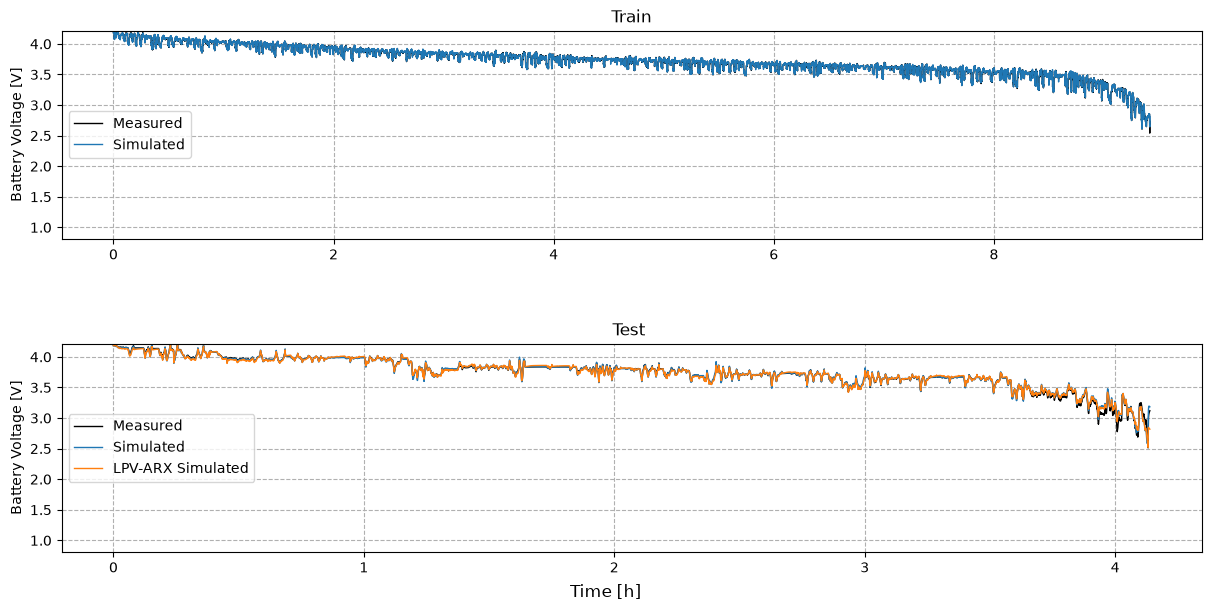

In [2]:
cell_type = "nmc"
input_output_configuration = 2  # Choose 1, 2, 3, or 4

configurations = {
    1: {"flags": {"I_sum": False, "V_op": False}, "model": "Base_300_epochs_1"},
    2: {"flags": {"I_sum": True, "V_op": False}, "model": "int_1000_epochs_1"},
    3: {"flags": {"I_sum": False, "V_op": True}, "model": "Only_Vop_100_epochs_1"},
    4: {"flags": {"I_sum": True, "V_op": True}, "model": "Vop_200_epochs_1"}
}

config = configurations[input_output_configuration]

datasets, sys_data_dict = dl.load_cell_data(cell=cell_type, flags=config["flags"])
train, val, test = sys_data_dict["train"], sys_data_dict["val"], sys_data_dict["test"]
sys = deepSI.load_system(f'Models/{cell_type}/{config["model"]}')
dl.print_error_and_plot(sys, train, test, stack_vertical=True, line_width=1.0, cell=cell_type, pbid=True)

d:\Anaconda\envs\OldDeepSI\Lib\site-packages\deepSI\systems\system.py:17: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(file)


Train errors (RMSE, NRMS, MAE) = (7.619 mV, 0.077, 4.984 mV)
Test  errors (RMSE, NRMS, MAE) = (7.229 mV, 0.118, 4.800 mV)
PyBatteryID Test  errors (RMSE, NRMS, MAE) = (7.785 mV, 0.128, 5.283 mV)
Region A -- red: (RMSE, MAE) = (6.845182624900282 mV, 4.423177027284996 mV)
Region B -- green: (RMSE, MAE) = (9.07665447544701 mV, 6.904568365864689 mV)
PyBatteryID Region A -- red: (RMSE, MAE) = (7.959350217498246 mV, 5.268802277950662 mV)
PyBatteryID Region B -- green: (RMSE, MAE) = (6.7334898121144215 mV, 5.3672193033580236 mV)


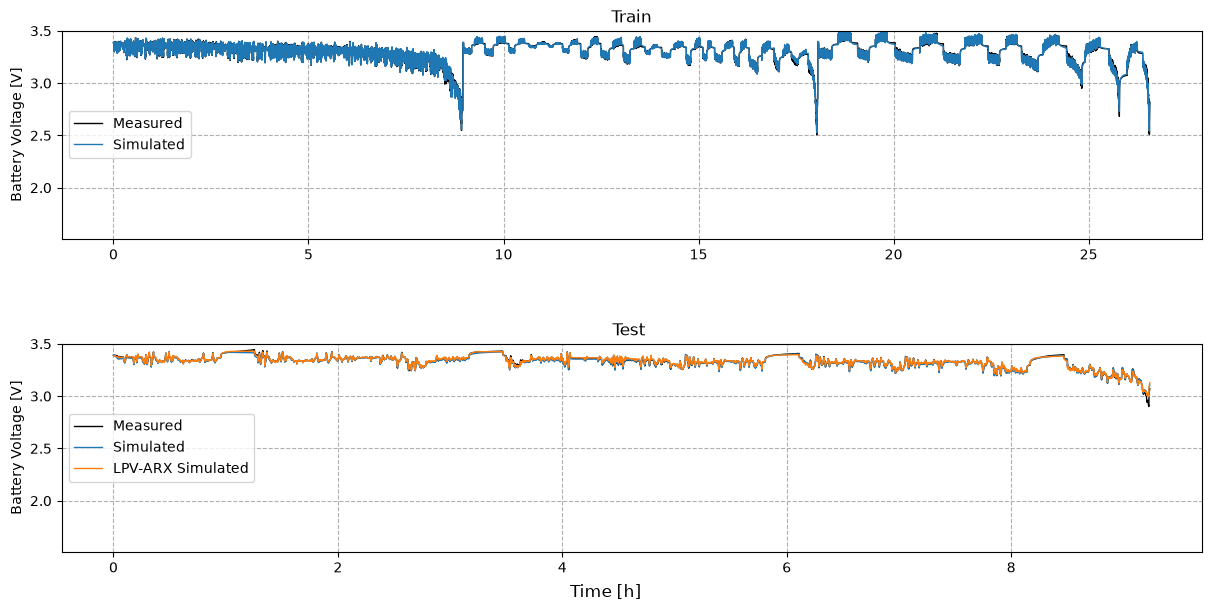

In [ ]:
cell_type = "lfp"
datasets, sys_data_dict = dl.load_cell_data(cell=cell_type, flags={"I_sum": True, "V_op": False})
train = sys_data_dict["train_comb"]
test   = sys_data_dict.get("test", None)
sys = deepSI.load_system("Models/lfp/int_1000_epochs_1")
dl.print_error_and_plot(sys, train, test, stack_vertical=True, line_width = 1.0, cell=cell_type, pbid=True)

d:\Anaconda\envs\OldDeepSI\Lib\site-packages\deepSI\systems\system.py:17: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(file)


Train errors (RMSE, NRMS, MAE) = (5.017 mV, 0.020, 3.307 mV)
Test Cold errors (RMSE, NRMS, MAE) = (27.360 mV, 0.106, 9.718 mV)
PyBatteryID Test Cold errors (RMSE, NRMS, MAE) = (20.229 mV, 0.079, 10.644 mV)
Test Normal errors (RMSE, NRMS, MAE) = (14.509 mV, 0.060, 7.298 mV)
PyBatteryID Test Normal errors (RMSE, NRMS, MAE) = (18.573 mV, 0.077, 9.118 mV)
Test Hot errors (RMSE, NRMS, MAE) = (6.973 mV, 0.031, 4.436 mV)
PyBatteryID Test Hot errors (RMSE, NRMS, MAE) = (8.707 mV, 0.038, 5.835 mV)


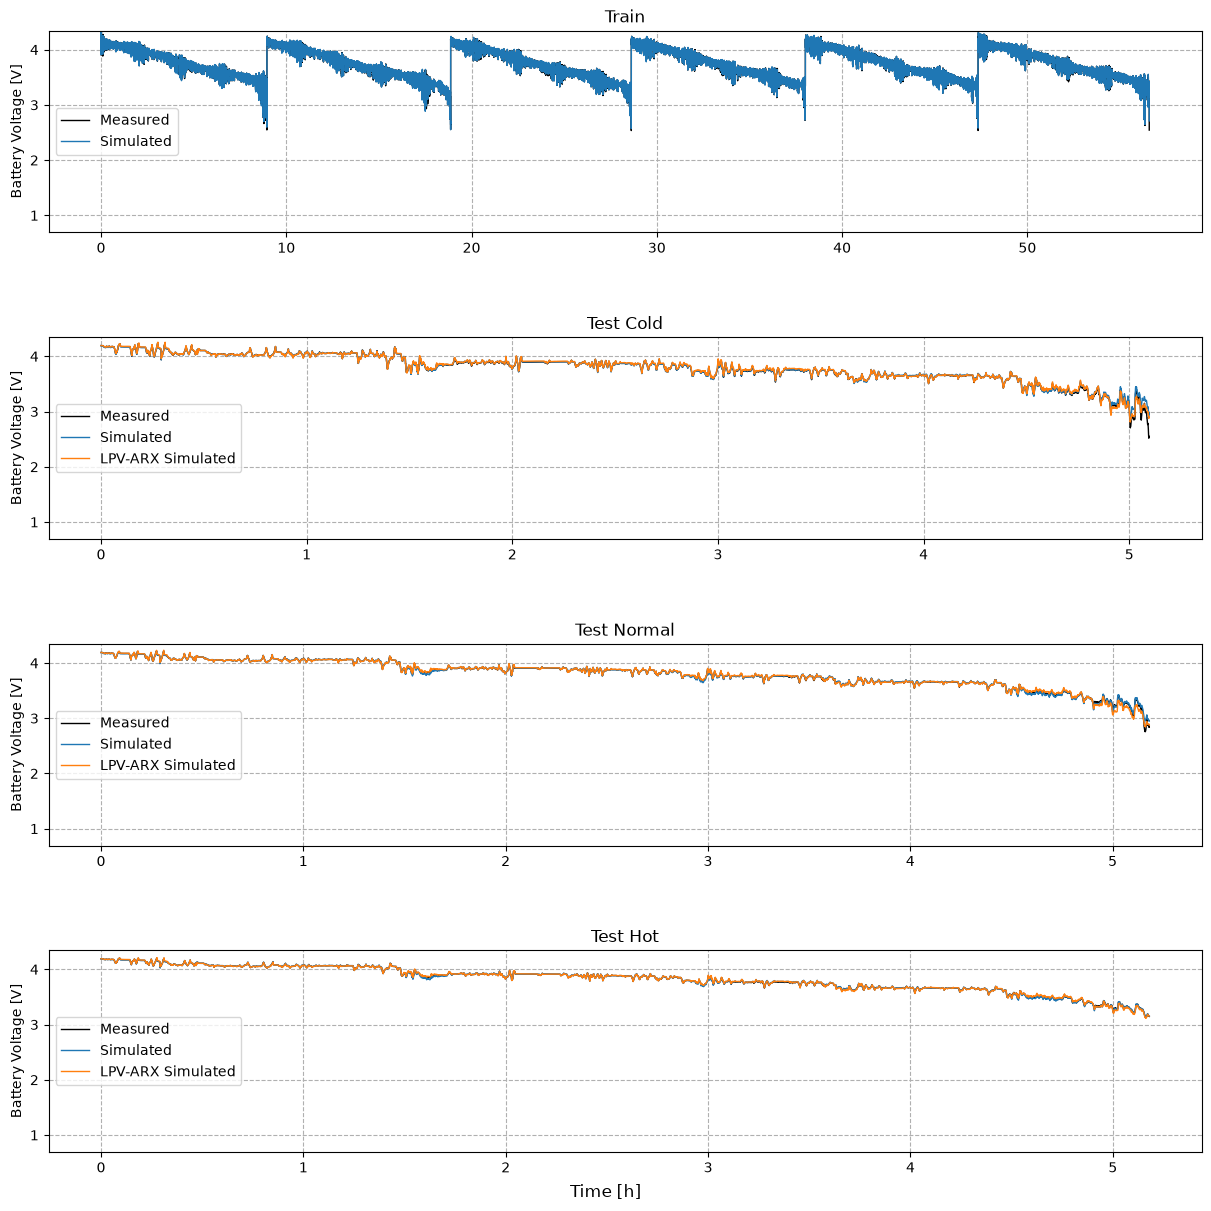

In [ ]:
cell_type = "nmc_temp"
datasets, sys_data_dict = dl.load_cell_data(cell=cell_type, flags={"temp":True, "I_sum": True})
train = sys_data_dict.get("train_comb")
test = [sys_data_dict.get("test_cold"),sys_data_dict.get("test_normal"),sys_data_dict.get("test_hot")]
sys = deepSI.load_system("Models/nmc_temp/int_600_epochs_1")
dl.print_error_and_plot(sys, train, test, stack_vertical=True, line_width = 1.0, cell=cell_type, pbid=True)

Initilizing the model and optimizer
Size of the training array =  340.8 MB
N_training_samples = 203030, batch_size = 256, N_batch_updates_per_epoch = 793


  0%|          | 0/793 [00:00<?, ?it/s]

1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1 1 2 2 1 1 2 1 1 2 2 2 2 1 1 2 1 1 2 2 1 1 1 2 2 2 1 1 2 2 1 1 2 2 2 2 2 2 2 2 2 2 3 2 3 3 3 2 3 3 3 3 3 2 2 2 3 3 3 3 3 3 2 3 3 3 3 1 3 3 3 3 4 3 3 4 3 3 4 4 4 4 3 1 4 4 4 4 4 4 4 4 4 4 4 4 4 5 5 5 4 4 4 5 5 1 5 5 5 5 5 5 5 5 5 1 5 5 5 1 5 5 5 6 5 1 1 5 5 5 6 5 6 6 6 6 6 5 6 6 6 6 6 6 6 6 5 6 6 6 6 7 7 7 6 7 7 1 6 7 7 7 1 8 7 7 7 7 8 8 8 8 8 8 8 8 8 8 9 9 9 9 9 9 10 10 10 10 1 11 10 11 11 12 12 12 12 12 12 12 12 13 13 13 13 15 15 16 18 18 17 22 27 77 1 17 87 27 93 2 ########## New lowest validation loss achieved ########### sim-NRMS = 1.0338955772812708
It  793, sqrt loss  0.2053, Val sim-NRMS  1.034, Time Loss: 99.7%, data: 0.3%, val: 0.0%, 7.93e+02 its/val,  2.4 batches/sec
Waiting for started validation process to finish and one last validation... (receiving = True)Recv done... Done!
Loaded model with best known validation sim-NRMS of 0.2707 which happened on epoch 793 (epoch_id=1.00)

d:\Anaconda\envs\OldDeepSI\Lib\site-packages\deepSI\fit_systems\fit_system.py:501: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.__dict__ = torch.load(file)


Train errors (RMSE, NRMS, MAE) = (67.722 mV, 0.271, 47.247 mV)
Test Cold errors (RMSE, NRMS, MAE) = (42.472 mV, 0.165, 32.426 mV)
PyBatteryID Test Cold errors (RMSE, NRMS, MAE) = (20.229 mV, 0.079, 10.644 mV)
Test Normal errors (RMSE, NRMS, MAE) = (39.379 mV, 0.163, 25.819 mV)
PyBatteryID Test Normal errors (RMSE, NRMS, MAE) = (18.573 mV, 0.077, 9.118 mV)
Test Hot errors (RMSE, NRMS, MAE) = (40.706 mV, 0.179, 32.884 mV)
PyBatteryID Test Hot errors (RMSE, NRMS, MAE) = (8.707 mV, 0.038, 5.835 mV)


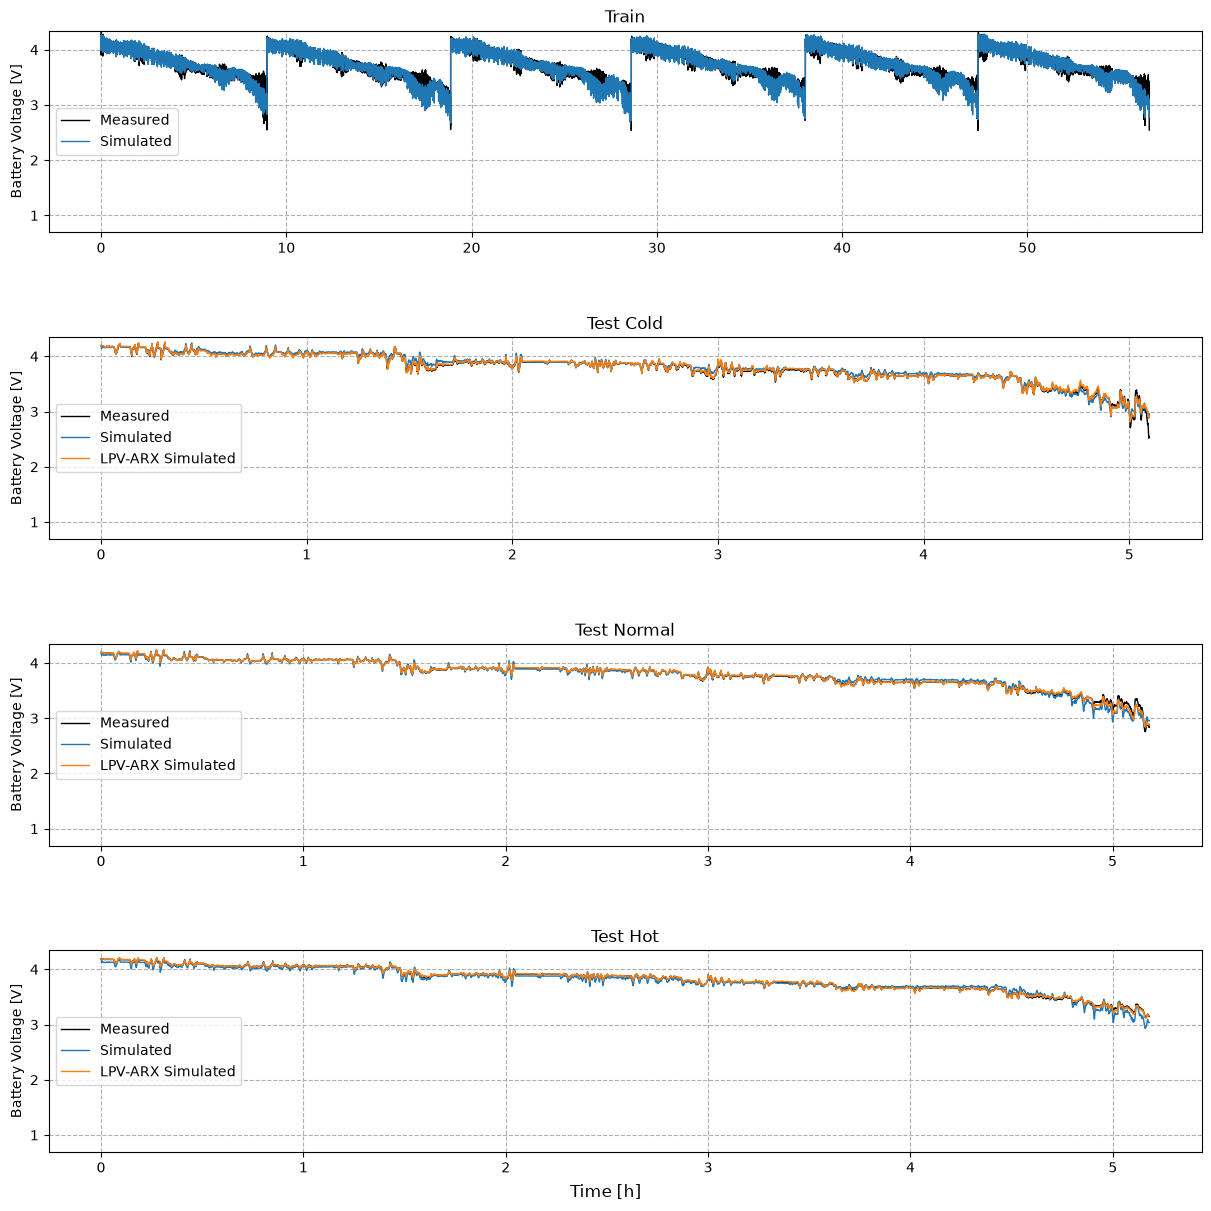

In [ ]:
cell_type = "nmc_temp"  # "nmc", "lfp", or "nmc_temp"
input_output_configuration = 2  # 1=base, 2=integrator, 3=overpotential, 4=both
epochs, runs = 1, 1

configurations = {
    1: {"flags": {"I_sum": False, "V_op": False}, "name": "base"},
    2: {"flags": {"I_sum": True, "V_op": False}, "name": "integrator"},
    3: {"flags": {"I_sum": False, "V_op": True}, "name": "vop"},
    4: {"flags": {"I_sum": True, "V_op": True}, "name": "integrator_vop"}
}

config = configurations[input_output_configuration]
datasets, sys_data_dict = dl.load_cell_data(cell=cell_type, flags=config["flags"])

if cell_type == "nmc":
    train = sys_data_dict["train"]
    test = sys_data_dict["test"]
else:
    train = sys_data_dict["train_comb"]
    test = sys_data_dict["test"] if cell_type == "lfp" else [sys_data_dict["test_cold"], sys_data_dict["test_normal"], sys_data_dict["test_hot"]]

for i in range(1, runs + 1):
    sys = LPV_single_encoder(nx=5, Np=3, na=10, nb=10, feedthrough=True, include_u_in_p=False, f_net_kwargs={"F": 10})
    start_time = time.time()
    sys.fit(train, train, epochs=epochs, loss_kwargs={"nf": 100, "loss_nf_cutoff": 0.20**2}, concurrent_val=True)
    elapsed_time = time.time() - start_time
    hours, rem = divmod(elapsed_time, 3600)
    minutes, seconds = divmod(rem, 60)
    print(f"Fitting with {epochs} epochs took {int(hours)}h {int(minutes)}m {seconds:.2f}s")
    print(f"Error for {cell_type}_{config['name']}_{epochs}_epochs_{i}:")

    dl.print_error_and_plot(sys, train, test, stack_vertical=True, line_width=1.0, cell=cell_type, pbid=True)
    sys.save_system(f"Models/{cell_type}/{config['name']}_{epochs}_epochs_{i}")